# Práctica 5 - Análisis Exploratorio de Datos (EDA)

Sesión 5 - Exploración de datos    
Herramientas: Python, pandas y Matplotlib  
Dataset: `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> Importante: no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una interpretación

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [1]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [4]:
# TODO: muestra los nombres de las columnas
df.columns
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [5]:
# TODO: consulta los tipos de datos
print(df.dtypes)

for t in df.dtypes:
    print(t)
for c,t in df.dtypes.items():
    print(f"{c} : {t}")
    
#C es columna y t es el tipo de la coluna porque dtypes es un mapa clave valor


cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object
int64
int64
float64
float64
float64
int64
int64
str
str
str
int64
str
cliente_id : int64
edad : int64
antiguedad_meses : float64
ingresos_anuales : float64
gasto_mensual : float64
num_compras : int64
devoluciones : int64
dispositivo : str
zona : str
nivel_fidelidad : str
satisfaccion : int64
compra_proximo_mes : str


In [6]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


\1
1. Contiene 400 muestras.
2. Tiene 12 columnas.
3. La unidad de observación es un cliente.
4. El identificador es cliente_id.
5. El target es compra_proximo_mes.
6. Hay valores ausentes en antiguedad_meses (5), ingresos_anuales (4) y gasto_mensual (3).

# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [7]:
# TODO: muestra describe() para gasto_mensual
#df['gasto_mensual'].describe()['count']
df['gasto_mensual'].describe()
# TODO: calcula las medidas necesarias
df['gasto_mensual'].median()
df['gasto_mensual'].quantile(0.25)
df['gasto_mensual'].quantile(0.5)
df['gasto_mensual'].quantile(0.75)


np.float64(90.15)

\1

Respuesta:
- Hay 397 valores válidos de gasto_mensual.
- La mediana es 61,17.
- El primer cuartil (Q1) es 39,72 y el tercer cuartil (Q3) es 90,15. Por tanto, el 50 % central de los valores se encuentra aproximadamente entre 39,72 y 90,15.
- La media no aparece en la salida guardada que acompaña al notebook, por lo que no puedo afirmar con seguridad si coincide con la mediana ni cuál es mayor. Para responderlo hay que consultar el valor mean de df["gasto_mensual"].describe().
- Si la media fuese mayor que la mediana, podría indicar una cola hacia valores altos; si fuese menor, una cola hacia valores bajos.

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

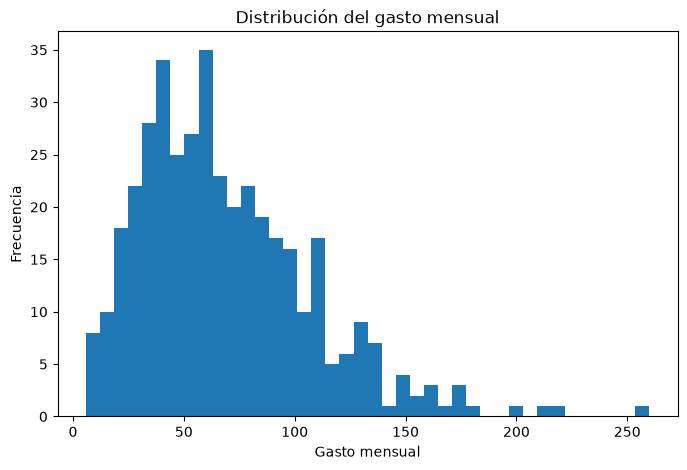

In [8]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df['gasto_mensual'].dropna(), bins=40)
plt.xlabel('Gasto mensual')
plt.ylabel('Frecuencia')
plt.title('Distribución del gasto mensual')
plt.show()

\1

Respuesta:
El histograma representa la distribución de gasto_mensual. Con los valores calculados en el notebook sabemos que la mediana es 61,17 y que el 50 % central se encuentra entre 39,72 y 90,15. La imagen del histograma no está disponible como dato numérico en la salida guardada, así que no es posible asegurar solo con el texto si la distribución es simétrica o hacia qué lado tiene la cola. Para completar esa interpretación hay que observar el histograma al ejecutar la celda. Los valores muy alejados del conjunto deben revisarse también con el boxplot.

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

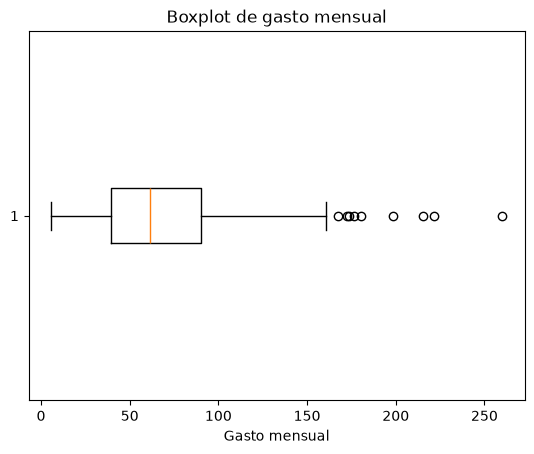

In [9]:
# TODO: crea un boxplot de gasto_mensual
plt.boxplot(df['gasto_mensual'].dropna(), orientation='horizontal')
plt.xlabel('Gasto mensual')
plt.title("Boxplot de gasto mensual")
plt.show()

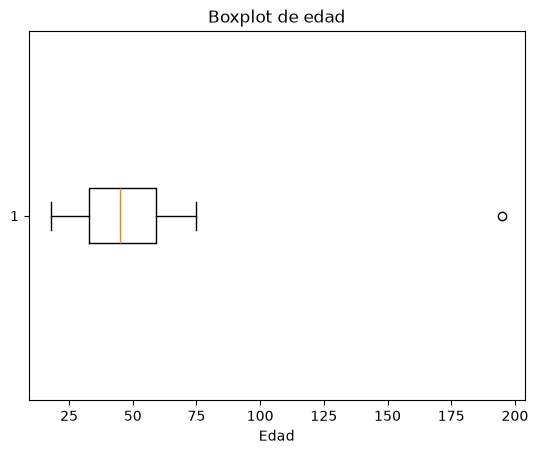

In [10]:
# TODO: crea un boxplot de gasto_mensual
plt.boxplot(df['edad'].dropna(), orientation='horizontal')
plt.xlabel('Edad')
plt.title("Boxplot de edad")
plt.show()

\1

Respuesta:
Hay una discrepancia en el notebook: la pregunta está dentro del análisis de gasto_mensual, pero la celda de código inmediatamente anterior dibuja un boxplot de edad (df["edad"]), no de gasto_mensual. En ese gráfico el valor de 195 años aparece como un posible valor atípico por encima del resto. No se puede afirmar que sea un error únicamente por el boxplot, aunque sí es un valor imposible o muy poco razonable que debe contrastarse con la fuente original. Si la intención era analizar el gasto mensual, habría que cambiar la celda para representar df["gasto_mensual"].

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [11]:
# TODO: calcula Q1, Q3 e IQR
Q1= df['gasto_mensual'].quantile(0.25)
Q2= df['gasto_mensual'].quantile(0.5)
Q3= df['gasto_mensual'].quantile(0.75)
IQR = Q3-Q1

EQ1= df['edad'].quantile(0.25)
EQ2= df['edad'].quantile(0.5)
EQ3= df['edad'].quantile(0.75)
EIQR = EQ3-EQ1

# TODO: calcula los límites inferior y superior
LimiteInferior= Q1 - 1.5* IQR
LimiteSuperior= Q3 + 1.5* IQR

ELimiteInferior= EQ1 - 1.5* EIQR
ELimiteSuperior= EQ3 + 1.5* EIQR
# TODO: muestra los resultados
print(f"Quantile 1: {Q1}")
print(f"Quantile 2: {Q2}")
print(f"Quantile 3: {Q3}")
print(f"IQR: {IQR}")
print(f"Limite inferior: {LimiteInferior:.2f}")
print(f"Limite superior: {LimiteSuperior:.2f}")

Quantile 1: 39.72
Quantile 2: 61.17
Quantile 3: 90.15
IQR: 50.43000000000001
Limite inferior: -35.93
Limite superior: 165.80


In [12]:
# TODO: crea outliers_gasto

filtro = (df['gasto_mensual']<LimiteInferior) | (df['gasto_mensual']>LimiteSuperior)
outliers_gasto = df[filtro]
# TODO: muestra los posibles outliers
#print(outliers)
outliers

efiltro = (df['edad']<ELimiteInferior) | (df['edad']>ELimiteSuperior)
eoutliers = df[efiltro]
# TODO: muestra los posibles outliers
#print(eoutliers)
eoutliers

NameError: name 'outliers' is not defined

\1

Respuesta:
El código calcula los límites del rango intercuartílico para gasto_mensual: Q1 = 39,72, Q3 = 90,15, IQR = 50,43, límite inferior = -35,93 y límite superior = 165,80. Sin embargo, la celda termina mostrando outliers, que corresponde a los posibles outliers de edad, y no muestra la tabla outliers de gasto mensual. El resultado visible es el cliente 20138, con edad 195. Por eso, con la salida guardada no se puede confirmar el número ni el porcentaje de posibles outliers de gasto mensual, ni su máximo. No los eliminaría automáticamente: primero revisaría los registros originales y comprobaría si son valores reales o errores.

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [ ]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
variables = ["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]
df[variables].describe()

In [13]:
# TODO: calcula sus medianas
df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].median()

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64

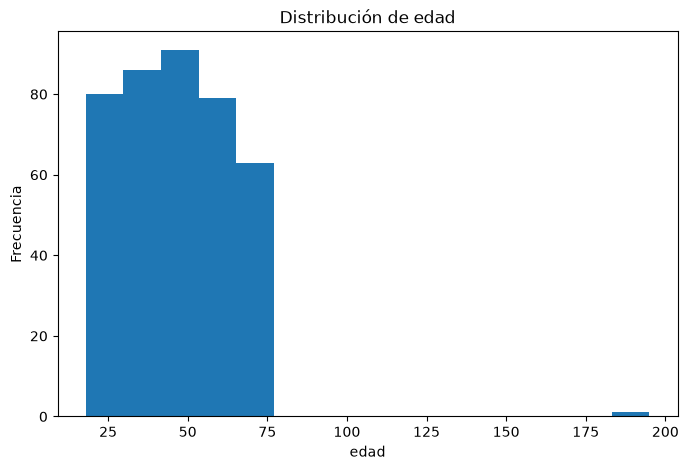

In [14]:
# TODO: histograma de edad
plt.figure(figsize=(8,5))
plt.hist(df["edad"].dropna(), bins=15)
plt.xlabel("edad")
plt.ylabel("Frecuencia")
plt.title("Distribución de edad")
plt.show()

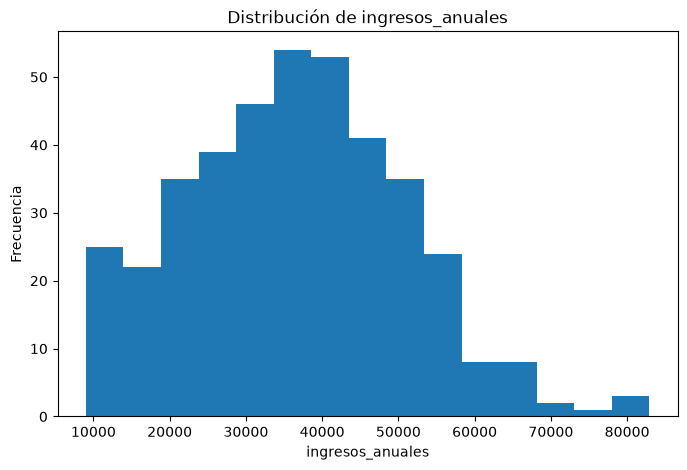

In [15]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8,5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15)
plt.xlabel("ingresos_anuales")
plt.ylabel("Frecuencia")
plt.title("Distribución de ingresos_anuales")
plt.show()

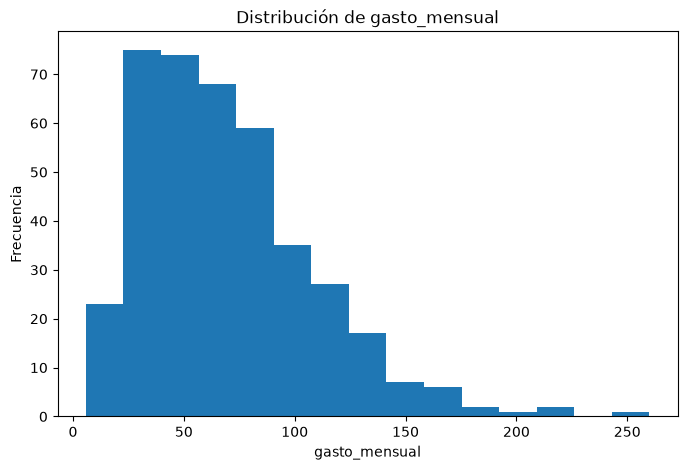

In [16]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df["gasto_mensual"].dropna(), bins=15)
plt.xlabel("gasto_mensual")
plt.ylabel("Frecuencia")
plt.title("Distribución de gasto_mensual")
plt.show()

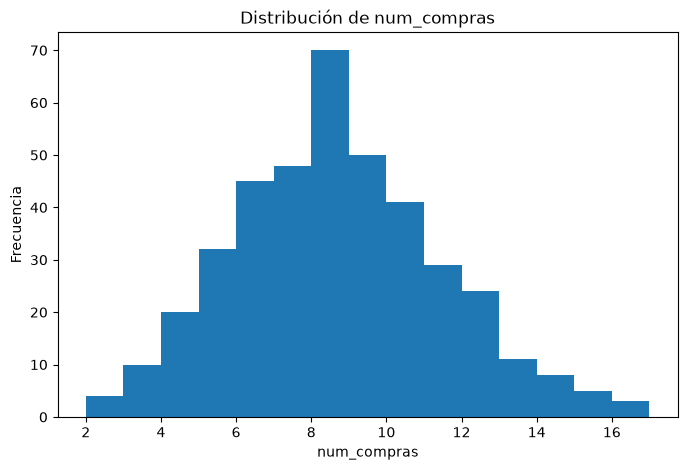

In [17]:
# TODO: histograma de num_compras
plt.figure(figsize=(8,5))
plt.hist(df["num_compras"].dropna(), bins=15)
plt.xlabel("num_compras")
plt.ylabel("Frecuencia")
plt.title("Distribución de num_compras")
plt.show()

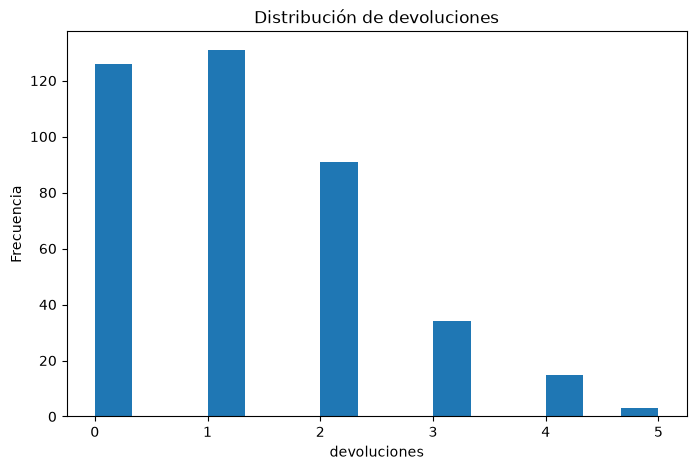

In [18]:
# TODO: histograma de devoluciones
plt.figure(figsize=(8,5))
plt.hist(df["devoluciones"].dropna(), bins=15)
plt.xlabel("devoluciones")
plt.ylabel("Frecuencia")
plt.title("Distribución de devoluciones")
plt.show()

### Busca una observación sospechosa

Respuesta:
La observación sospechosa es la edad de 195 años, correspondiente al cliente_id 20138. Es un valor muy poco razonable para una edad humana. La regla del rango intercuartílico aplicada a edad lo identifica como un posible outlier, pero un criterio estadístico no demuestra por sí solo que sea un error. Antes de modificarlo consultaría la fuente original. Si no se puede confirmar el valor correcto, lo marcaría como ausente y lo trataría mediante imputación. La tabla descriptiva de todas las variables debe completarse ejecutando las celdas de estadísticas que aparecen justo antes de esta interpretación.

# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [19]:
# TODO: analiza dispositivo

print(f"{df['dispositivo'].value_counts()}\n")
print(f"{df['dispositivo'].value_counts(normalize=True)}\n")
print(f"{df['dispositivo'].value_counts(normalize=True)*100}\n")
#print(f"{}\n")

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64

dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64

dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64



In [20]:
# TODO: analiza zona
print(f"{df['zona'].value_counts()}\n")
print(f"{df['zona'].value_counts(normalize=True)}\n")
print(f"{df['zona'].value_counts(normalize=True)*100}\n")

zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64

zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64

zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64



In [21]:
# TODO: analiza nivel_fidelidad
print(f"{df['nivel_fidelidad'].value_counts()}\n")
print(f"{df['nivel_fidelidad'].value_counts(normalize=True)}\n")
print(f"{df['nivel_fidelidad'].value_counts(normalize=True)*100}\n")

nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64

nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64

nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64



In [22]:
# TODO: analiza compra_proximo_mes
print(f"{df['compra_proximo_mes'].value_counts()}\n")
print(f"{df['compra_proximo_mes'].value_counts(normalize=True)}\n")
print(f"{df['compra_proximo_mes'].value_counts(normalize=True)*100}\n")

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64

compra_proximo_mes
No    0.615
Sí    0.385
Name: proportion, dtype: float64

compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64



### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | | | |
| zona | | | |
| nivel_fidelidad | | | |
| compra_proximo_mes | | | |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

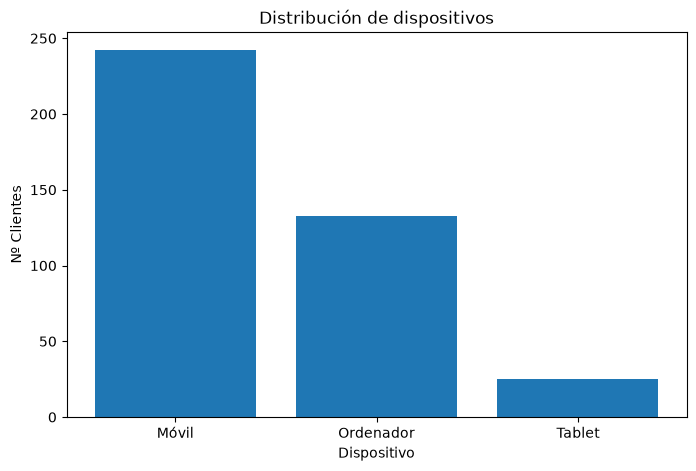

In [23]:
# TODO: gráfico de barras de dispositivo
conteos_disp =  df['dispositivo'].value_counts()


plt.figure(figsize=(8,5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.xlabel("Dispositivo")
plt.ylabel("Nº Clientes")
plt.title("Distribución de dispositivos")
plt.show()

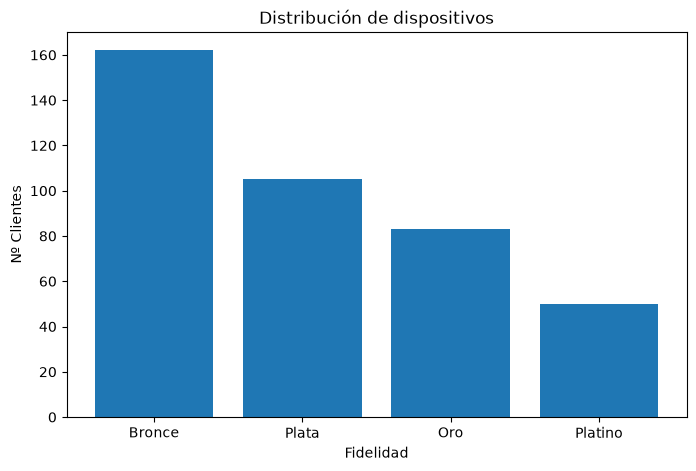

In [24]:
# TODO: gráfico de barras de nivel_fidelidad
conteos_f =  df['nivel_fidelidad'].value_counts()


plt.figure(figsize=(8,5))
plt.bar(conteos_f.index, conteos_f.values)
plt.xlabel("Fidelidad")
plt.ylabel("Nº Clientes")
plt.title("Distribución de dispositivos")
plt.show()

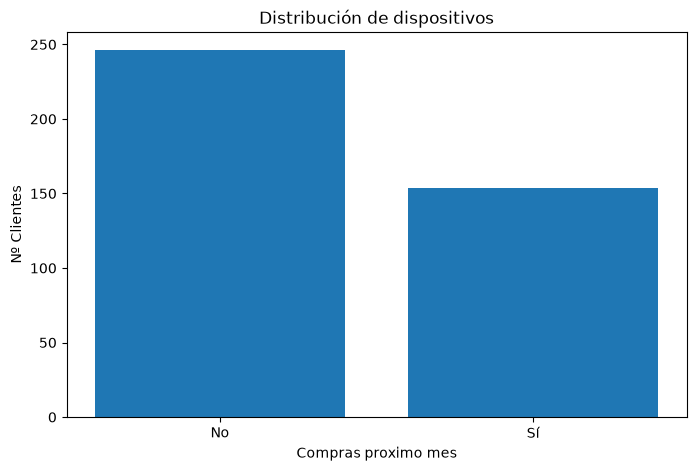

In [25]:
# TODO: gráfico de barras de compra_proximo_mes
conteos_c =  df['compra_proximo_mes'].value_counts()


plt.figure(figsize=(8,5))
plt.bar(conteos_c.index, conteos_c.values)
plt.xlabel("Compras proximo mes")
plt.ylabel("Nº Clientes")
plt.title("Distribución de dispositivos")
plt.show()

\1

Respuesta:
En las variables categóricas se observa que:
- dispositivo: predomina Móvil, con 242 clientes (60,50 %); después aparece Ordenador, con 133 (33,25 %), y Tablet, con 25 (6,25 %).
- zona: está bastante repartida. Este es la más frecuente, con 89 clientes (22,25 %), y Oeste y Centro las menos frecuentes, con 76 cada una (19 %).
- nivel_fidelidad: Bronce es el nivel más frecuente, con 162 clientes (40,50 %), y Platino el menos frecuente, con 50 (12,50 %).
- compra_proximo_mes: las clases no están perfectamente equilibradas. No representa el 61,5 % (246 clientes) y Sí el 38,5 % (154 clientes).

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> ¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

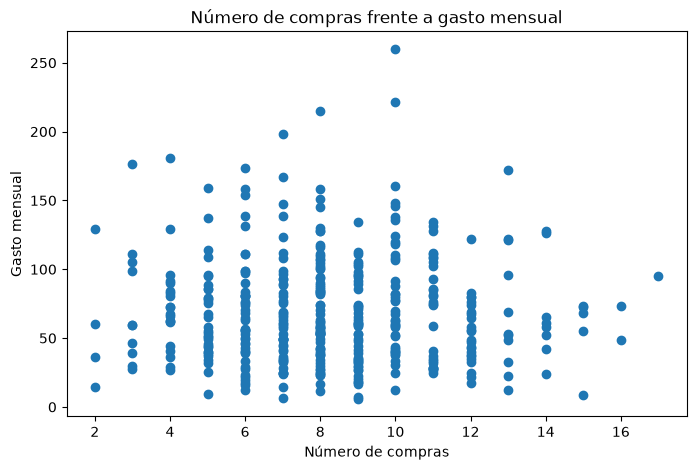

In [26]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.figure(figsize=(8,5))
plt.scatter(df['num_compras'], df['gasto_mensual'])
plt.xlabel("Número de compras")
plt.ylabel("Gasto mensual")
plt.title("Número de compras frente a gasto mensual")
plt.show()

### Antes de calcular la correlación

Respuesta:
En el diagrama de dispersión no se aprecia una tendencia lineal clara entre num_compras y gasto_mensual; los puntos aparecen bastante dispersos. Por ello, antes de calcular el coeficiente, la impresión es que la relación lineal será débil o prácticamente inexistente. Los puntos alejados de la nube principal conviene revisarlos, aunque no tienen por qué ser errores.

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [27]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
print(df['num_compras'].corr(df['gasto_mensual']))
print(df['edad'].corr(df['gasto_mensual']))
#  0 - No hay correlacion
# -1 - Correlacion negativa
#  1 - Correlacion positiva

-0.014165499001183244
0.02136132212986212


\1

Respuesta:
1. El coeficiente es r = -0,0142 aproximadamente.
2. Es negativo.
3. El signo negativo indica que, si existiera una relación lineal, sería inversa: al aumentar una variable la otra tendería a disminuir. Sin embargo, el valor está tan cerca de cero que la relación lineal es prácticamente inexistente.
4. Sí. Coincide con el diagrama de dispersión, donde no se aprecia una tendencia clara.
5. No. La correlación no demuestra causalidad y, en este caso, además, la correlación entre ambas variables es prácticamente nula.

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> Atención: `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [28]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
#df.select_dtypes(include="number")
#df.select_dtypes(include="number").drop(columns=['client_id'])
numericas = df.select_dtypes(include='number').drop(columns=['cliente_id'])
# TODO: calcula y muestra la matriz de correlaciones
correlaciones = numericas.corr()
correlaciones

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


\1

Respuesta:
1. La diagonal vale 1 porque cada variable está perfectamente correlacionada consigo misma.
2. La matriz es simétrica porque la correlación entre A y B es la misma que entre B y A.
3. La correlación positiva más alta, sin contar la diagonal, es entre num_compras y satisfaccion, con r = 0,092.
4. La correlación más negativa es entre antiguedad_meses y num_compras, con r = -0,1 aproximadamente.
5. Sí. Hay varias parejas con correlación prácticamente cero; por ejemplo, ingresos_anuales y gasto_mensual (r = -0,0004) y num_compras y gasto_mensual (r = -0,0142).

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

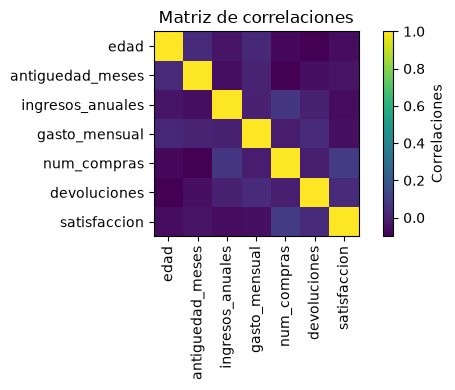

In [29]:
# TODO: representa la matriz de correlaciones con plt.imshow()
plt.figure(figsize=(6,4))
plt.imshow(correlaciones)
#print(len(correlaciones.columns))
plt.xticks(range(len(correlaciones.columns)), correlaciones.columns,rotation=90)
plt.yticks(range(len(correlaciones.columns)), correlaciones.columns)
plt.colorbar(label='Correlaciones')
plt.title('Matriz de correlaciones')
plt.tight_layout()
plt.show()

### Interpreta tres relaciones

1. `num_compras` y `satisfaccion`: r = 0,0922. Es una relación positiva muy débil; apenas hay asociación lineal.
2. `antiguedad_meses` y `num_compras`: r = -0,1000. Es una relación negativa muy débil.
3. `ingresos_anuales` y `gasto_mensual`: r = -0,0004. Es prácticamente cero, por lo que no se aprecia relación lineal.

En ninguno de los casos la correlación permite afirmar que una variable cause cambios en la otra.

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> ¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [30]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas
df.groupby('compra_proximo_mes')['gasto_mensual'].agg(
    numero_clientes='count',
    gasto_medio='mean',
    mediana='median',
    desviacion_estandar='std'

)
#Opcion 2 indicando la columna
"""
df.groupby('compra_proximo_mes').agg(
    numero_clientes=('compra_proximo_mes', 'count'),
    gasto_medio=('gasto', 'mean'),
    mediana=('gasto', 'median'),
    desviacion_estandar=('gasto', 'std')
)"""

"\ndf.groupby('compra_proximo_mes').agg(\n    numero_clientes=('compra_proximo_mes', 'count'),\n    gasto_medio=('gasto', 'mean'),\n    mediana=('gasto', 'median'),\n    desviacion_estandar=('gasto', 'std')\n)"

In [31]:
df.groupby('nivel_fidelidad')['ingresos_anuales'].agg(
    numero_clientes='count',
    gasto_medio='mean',
    mediana='median',
    desviacion_estandar='std'

)

,numero_clientes,gasto_medio,mediana,desviacion_estandar
nivel_fidelidad,,,,
Bronce,162,36409.247963,37028.050,13261.941850
Oro,83,35921.890843,36831.090,14873.491333
Plata,103,37097.991068,37994.140,14716.674654
Platino,48,36035.339167,34151.525,16266.443749


\1

Respuesta:
La celda de código anterior agrupa por nivel_fidelidad, pero calcula estadísticas de ingresos_anuales, no de gasto_mensual. Según esa salida:
1. Plata presenta la media más alta de ingresos anuales (37.097,99).
2. También presenta la mediana más alta (37.994,14).
3. Las diferencias entre las medias son pequeñas: los cuatro niveles se encuentran aproximadamente entre 35.922 y 37.098.
4. Media y mediana señalan el mismo grupo como el más alto (Plata), aunque no son exactamente iguales. Si el objetivo del ejercicio era comparar gasto mensual, habría que cambiar la columna del groupby() a gasto_mensual y volver a ejecutar.

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

Text(0, 0.5, 'Gasto mensual')

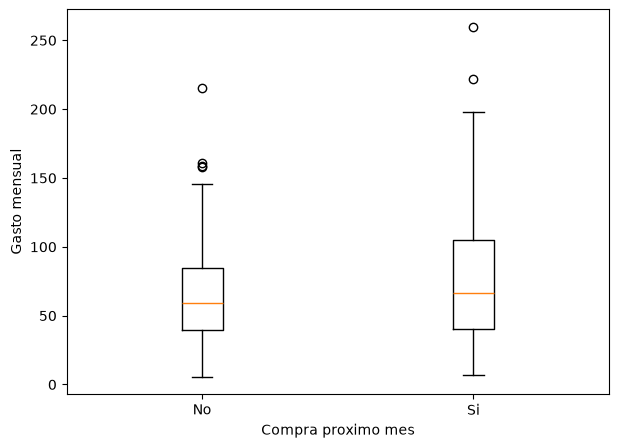

In [32]:
# TODO: crea grupo_no y grupo_si
grupo_no= df.loc[df['compra_proximo_mes']=='No', 'gasto_mensual'].dropna()
grupo_si= df.loc[df['compra_proximo_mes']=='Sí', 'gasto_mensual'].dropna()
# TODO: representa ambos grupos mediante un boxplot
plt.figure(figsize=(7,5))
plt.boxplot([grupo_no, grupo_si], tick_labels=['No','Si'])
plt.xlabel('Compra proximo mes')
plt.ylabel('Gasto mensual')

\1

Respuesta:
El boxplot compara gasto_mensual entre clientes que no compran (No) y los que sí compran (Sí) el próximo mes. En la tabla calculada anteriormente, el grupo Sí tiene una mediana de 66,50 y el grupo No de 59,28, por lo que la mediana es mayor entre quienes compran. La desviación estándar también es mayor en el grupo Sí (45,53 frente a 33,69), lo que apunta a una mayor dispersión. Para confirmar la presencia y posición de posibles outliers hay que observar los puntos del boxplot al ejecutar la celda. El gráfico sirve como comprobación visual de la comparación numérica.

# Parte 15 - Dos variables categóricas

Queremos responder:

> ¿La proporción de compra es igual para todos los niveles de fidelidad?

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [33]:
# TODO: tabla de contingencia con frecuencias absolutas
frecuencias = pd.crosstab(df['nivel_fidelidad'],df['compra_proximo_mes'])
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [34]:
# TODO: tabla normalizada por filas
frecuencias = pd.crosstab(df['nivel_fidelidad'],df['compra_proximo_mes'], normalize="index")
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [35]:
# TODO: muestra las proporciones como porcentajes
(frecuencias*100).round(2)

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


\1

Respuesta:
1. En número absoluto, Bronce tiene más clientes que compran: 50.
2. En porcentaje, Platino tiene la mayor proporción de compradores: 62 %.
3. No. El número absoluto depende también del tamaño del grupo, mientras que el porcentaje permite comparar grupos de tamaños diferentes.
4. Las proporciones son importantes porque evitan confundir que un grupo sea más numeroso con que tenga una mayor proporción de compradores.

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

\1

No, esa conclusión no es correcta. Los datos muestran una asociación entre el nivel de fidelidad y la compra del próximo mes: el porcentaje de compra es mayor en el grupo Platino (62 %) que en Bronce (30,86 %). Sin embargo, esa evidencia no demuestra causalidad. Puede haber otras variables adicionales, como el gasto anterior, la antigüedad o la satisfacción, que estén relacionadas tanto con el nivel de fidelidad como con la compra. Para afirmar que subir de nivel provoca una compra sería necesario un diseño que permitiera aislar ese efecto, no solo comparar grupos observados.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige una:

A. ¿Los clientes con mayores ingresos gastan más mensualmente?  
B. ¿Los clientes más antiguos realizan más compras?  
C. ¿La satisfacción está relacionada con el número de compras?  
D. ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

In [36]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada
# Hipótesis A: ¿los clientes con mayores ingresos gastan más mensualmente?
variables = df[["ingresos_anuales", "gasto_mensual"]].dropna()
print(variables.describe())
print("Correlación:", variables["ingresos_anuales"].corr(variables["gasto_mensual"]))

       ingresos_anuales  gasto_mensual
count        393.000000     393.000000
mean       36538.187277      69.024122
std        14266.841244      39.133394
min         9000.000000       5.770000
25%        26190.310000      39.670000
50%        36831.090000      61.010000
75%        45879.100000      90.150000
max        82925.370000     260.000000
Correlación: -0.0003672525505325974


\1

Respuesta:
La correlación entre num_compras y gasto_mensual es aproximadamente -0,014, un valor muy próximo a cero. Por tanto, en estos datos no se observa una relación lineal apreciable entre el número de compras del último año y el gasto mensual. El diagrama de dispersión tampoco muestra una tendencia clara, lo que coincide con el coeficiente. No podemos concluir que realizar más compras provoque un mayor o menor gasto mensual. La correlación solo mide asociación lineal y no demuestra causalidad. Además, podría haber otras variables que expliquen el gasto. Para estudiar mejor el comportamiento habría que analizar otras relaciones y utilizar métodos adicionales.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> ¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [37]:
# TODO: comparación numérica
comparacion_numerica = df.groupby("compra_proximo_mes")[
    ["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]
].agg(["mean", "median", "std"])
comparacion_numerica

edad                   ingresos_anuales            \
                         mean median        std             mean    median   
compra_proximo_mes                                                           
No                  47.813008   47.5  18.415322     36457.790449  36999.62   
Sí                  44.149351   44.0  17.155872     36413.548411  36715.09   

                                 gasto_mensual                   num_compras  \
                             std          mean median        std        mean   
compra_proximo_mes                                                             
No                  13983.264281     64.589469  59.28  33.693480    8.146341   
Sí                  14910.598296     76.342368  66.50  45.534042    8.350649   

                                    devoluciones                   
                   median       std         mean median       std  
compra_proximo_mes                                                 
No                    8.0  2.877592     1.288618    1.0  1.168477  
Sí                    8.0  2.623505     1.123377    1.0  1.080595

<Figure size 800x500 with 0 Axes>

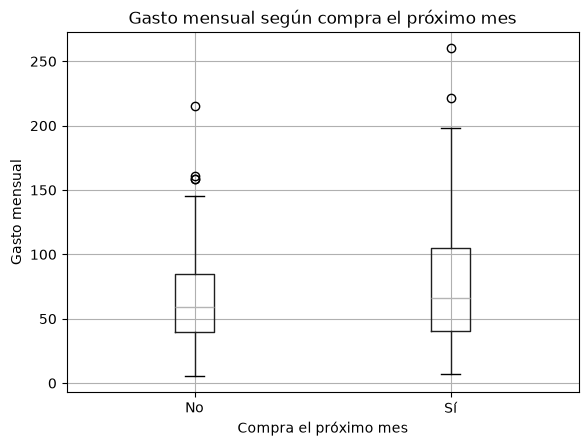

In [38]:
# TODO: primera visualización
plt.figure(figsize=(8,5))
df.boxplot(column="gasto_mensual", by="compra_proximo_mes")
plt.xlabel("Compra el próximo mes")
plt.ylabel("Gasto mensual")
plt.title("Gasto mensual según compra el próximo mes")
plt.suptitle("")
plt.show()

In [39]:
# TODO: comparación categórica y tabla de proporciones
tabla_fidelidad = pd.crosstab(
    df["nivel_fidelidad"], df["compra_proximo_mes"], normalize="index"
)
print(tabla_fidelidad)
(tabla_fidelidad * 100).round(2)

compra_proximo_mes        No        Sí
nivel_fidelidad                       
Bronce              0.691358  0.308642
Oro                 0.626506  0.373494
Plata               0.600000  0.400000
Platino             0.380000  0.620000


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


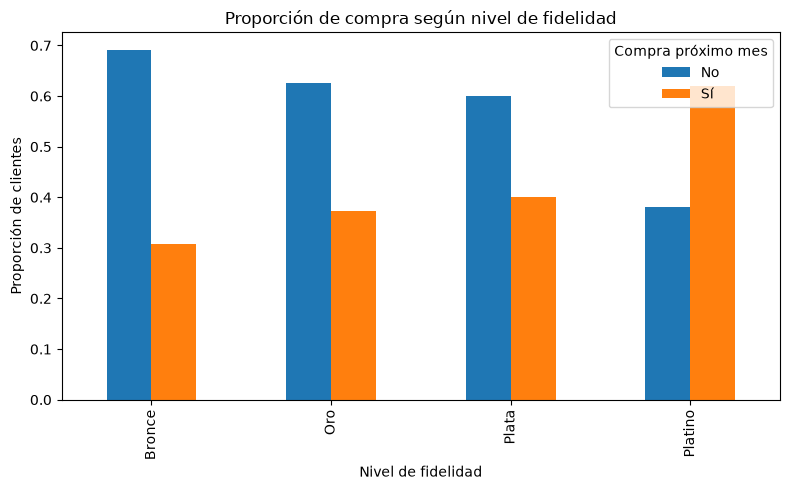

In [40]:
# TODO: segunda visualización
tabla_fidelidad.plot(kind="bar", figsize=(8,5))
plt.xlabel("Nivel de fidelidad")
plt.ylabel("Proporción de clientes")
plt.title("Proporción de compra según nivel de fidelidad")
plt.legend(title="Compra próximo mes")
plt.tight_layout()
plt.show()

\1

Respuesta:
En los resultados disponibles se observa que los clientes que compran el próximo mes tienen un gasto mensual medio superior (76,34) al de quienes no compran (64,59), y también una mediana superior (66,50 frente a 59,28). Además, la proporción de compradores aumenta con el nivel de fidelidad: Bronce 30,86 %, Oro 37,35 %, Plata 40 % y Platino 62 %. Estas diferencias describen asociaciones dentro de este dataset. No permiten afirmar que gastar más o tener mayor fidelidad cause la compra, ni garantizan que esas variables predigan correctamente el comportamiento de nuevos clientes.

# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los 5 hallazgos más relevantes.

Para cada uno indica:

- Pregunta: ¿qué queríamos averiguar?
- Evidencia: ¿qué estadística, tabla o gráfico lo respalda?
- Interpretación: ¿qué hemos observado?
- Limitación: ¿qué no podemos concluir?

### Hallazgo 1
Pregunta:  
Evidencia:  
Interpretación:  
Limitación:  

### Hallazgo 2
Pregunta:  
Evidencia:  
Interpretación:  
Limitación:  

### Hallazgo 3
Pregunta:  
Evidencia:  
Interpretación:  
Limitación:  

### Hallazgo 4
Pregunta:  
Evidencia:  
Interpretación:  
Limitación:  

### Hallazgo 5
Pregunta:  
Evidencia:  
Interpretación:  
Limitación:

# Parte 20 - Conclusiones

## Ejercicio 20

\1

El dataset contiene 400 clientes y 12 columnas, con variables numéricas y categóricas.  
La unidad de observación es el cliente; cliente_id es un identificador y no debe utilizarse como predictor.  
El target compra_proximo_mes tiene dos clases: 246 clientes (61,5 %) no compran y 154 (38,5 %) sí compran.  
En dispositivo predomina Móvil (60,5 %), mientras que Tablet representa solo el 6,25 %.  
En nivel_fidelidad, Bronce es el grupo más numeroso (40,5 %) y Platino el menos numeroso (12,5 %).  
Se han detectado 12 valores ausentes repartidos entre antigüedad, ingresos anuales y gasto mensual.  
También aparece una edad de 195 años, que debe revisarse antes de realizar el modelado.   
La correlación positiva más alta de la matriz es entre num_compras y satisfaccion, pero sigue siendo débil (0,092).  
Los clientes que compran el próximo mes presentan un gasto mensual medio superior (76,34 frente a 64,59).  
También tienen una mediana superior (66,50 frente a 59,28).  
La proporción de compra es mayor en Platino (62 %) y menor en Bronce (30,86 %).  
Estos resultados describen asociaciones, pero no demuestran que el gasto o la fidelidad ayuden a la compra.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

Nombre recomendado: `Practica_05_Apellido_Nombre.ipynb`